# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : fiqri alifsaputra
- NIM   : 241011402798
- Kelas : Reg C 

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [ ]:
# Import library yang diperbolehkan
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Dua digit terakhir NIM = 98
RANDOM_STATE = 98
np.set_printoptions(precision=4, suppress=True)


In [ ]:
def train_test_split(X, y, test_size=0.2, random_state=42):
    """Membagi data secara acak tanpa scikit-learn."""
    X = np.asarray(X)
    y = np.asarray(y)
    rng = np.random.RandomState(random_state)
    indices = rng.permutation(len(X))
    n_test = int(np.ceil(len(X) * test_size))
    test_idx = indices[:n_test]
    train_idx = indices[n_test:]
    return X[train_idx], X[test_idx], y[train_idx], y[test_idx]


class LinearRegression:
    """Regresi linear dengan normal equation."""
    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        X_bias = np.c_[np.ones(X.shape[0]), X]
        theta = np.linalg.pinv(X_bias) @ y
        self.intercept_ = theta[0]
        self.coef_ = theta[1:]
        return self

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return self.intercept_ + X @ self.coef_


class LinearRegressionGD:
    """Regresi linear dengan gradient descent; loss yang dicatat adalah MSE."""
    def __init__(self, learning_rate=0.01, n_iterations=1000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        self.intercept_ = 0.0
        self.coef_ = np.zeros(X.shape[1], dtype=float)
        self.loss_history_ = []
        n = len(y)
        for _ in range(self.n_iterations):
            pred = self.intercept_ + X @ self.coef_
            error = pred - y
            db = 2 * np.mean(error)
            dw = 2 * (X.T @ error) / n
            self.intercept_ -= self.learning_rate * db
            self.coef_ -= self.learning_rate * dw
            pred_new = self.intercept_ + X @ self.coef_
            self.loss_history_.append(np.mean((pred_new - y) ** 2))
        self.loss_history_ = np.asarray(self.loss_history_)
        return self

    def predict(self, X):
        return self.intercept_ + np.asarray(X, dtype=float) @ self.coef_


class LogisticRegression:
    """Regresi logistik biner dengan gradient descent."""
    def __init__(self, learning_rate=0.1, n_iterations=10000):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations

    @staticmethod
    def sigmoid(z):
        z = np.clip(z, -500, 500)
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)
        y = np.asarray(y, dtype=float).reshape(-1)
        n, d = X.shape
        self.intercept_ = 0.0
        self.coef_ = np.zeros(d, dtype=float)
        self.loss_history_ = []
        for _ in range(self.n_iterations):
            prob = self.sigmoid(self.intercept_ + X @ self.coef_)
            self.coef_ -= self.learning_rate * (X.T @ (prob - y)) / n
            self.intercept_ -= self.learning_rate * np.mean(prob - y)
            prob = np.clip(self.predict_proba(X), 1e-15, 1 - 1e-15)
            loss = -np.mean(y * np.log(prob) + (1 - y) * np.log(1 - prob))
            self.loss_history_.append(loss)
        self.loss_history_ = np.asarray(self.loss_history_)
        return self

    def predict_proba(self, X):
        return self.sigmoid(self.intercept_ + np.asarray(X, dtype=float) @ self.coef_)

    def predict(self, X, threshold=0.5):
        return (self.predict_proba(X) >= threshold).astype(int)


def accuracy_score(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    return np.mean(y_true == y_pred)


def confusion_matrix(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    # Susunan: [[TN, FP], [FN, TP]]
    return np.array([
        [np.sum((y_true == 0) & (y_pred == 0)), np.sum((y_true == 0) & (y_pred == 1))],
        [np.sum((y_true == 1) & (y_pred == 0)), np.sum((y_true == 1) & (y_pred == 1))]
    ])


def classification_metrics(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    tn, fp, fn, tp = cm.ravel()
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision,
        "Recall": recall,
        "F1-score": f1,
        "TN": tn, "FP": fp, "FN": fn, "TP": tp
    }


---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris data: 40
Shape X: (40, 1) | Shape y: (40,)


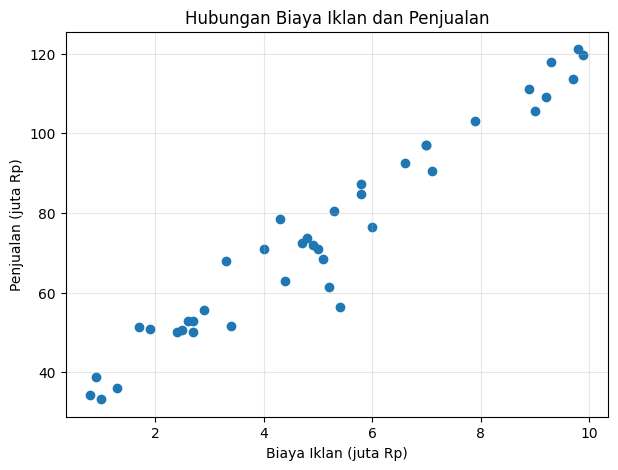

In [ ]:
# Jawaban A1
ads = pd.read_csv("Ads_Data.csv")
display(ads.head())
print("Jumlah baris data:", len(ads))

X = ads[["BiayaIklan"]].to_numpy(dtype=float)  # bentuk (n, 1)
y = ads["Penjualan"].to_numpy(dtype=float)
print("Shape X:", X.shape, "| Shape y:", y.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X[:, 0], y)
plt.title("Hubungan Biaya Iklan dan Penjualan")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.grid(alpha=0.3)
plt.show()


### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [ ]:
# Jawaban A2
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [ ]:
# Jawaban A3
linear_model = LinearRegression().fit(X_train, y_train)
b = linear_model.intercept_
m = linear_model.coef_[0]
print(f"Intercept (b): {b:.4f}")
print(f"Koefisien (m): {m:.4f}")
print(f"Persamaan regresi: ŷ = {b:.4f} + ({m:.4f} × BiayaIklan)")


Intercept (b): 29.4311
Koefisien (m): 9.0081
Persamaan regresi: ŷ = 29.4311 + (9.0081 × BiayaIklan)


**Jawaban A3 (interpretasi):**

Koefisien `m` menunjukkan perubahan rata-rata penjualan yang diperkirakan ketika biaya iklan naik 1 juta rupiah. Jika `m` positif, kenaikan biaya iklan berkaitan dengan kenaikan penjualan sebesar nilai `m` juta rupiah, dengan asumsi hubungan linear pada data ini. Intercept `b` adalah penjualan yang diprediksi saat biaya iklan bernilai nol; nilai ini merupakan bagian dari persamaan dan belum tentu bermakna secara praktis jika biaya nol berada di luar rentang data.


### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [ ]:
# Jawaban A4
def regression_metrics(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    errors = y_true - y_pred
    mae = np.mean(np.abs(errors))
    mse = np.mean(errors ** 2)
    rmse = np.sqrt(mse)
    denominator = np.sum((y_true - np.mean(y_true)) ** 2)
    r2 = 1 - np.sum(errors ** 2) / denominator if denominator != 0 else np.nan
    return {"MAE": mae, "MSE": mse, "RMSE": rmse, "R2": r2}

y_train_pred = linear_model.predict(X_train)
y_test_pred = linear_model.predict(X_test)
metrics_table = pd.DataFrame([
    {"Data": "Training", **regression_metrics(y_train, y_train_pred)},
    {"Data": "Testing", **regression_metrics(y_test, y_test_pred)}
]).set_index("Data")
display(metrics_table.round(4))


,MAE,MSE,RMSE,R2
Data,,,,
Training,3.5538,18.2134,4.2677,0.9704
Testing,8.3125,110.1016,10.4929,0.8446


**Jawaban A4 (analisis):**

MAE adalah rata-rata besar kesalahan prediksi, sedangkan RMSE juga mengukur kesalahan dalam satuan juta rupiah tetapi memberi penalti lebih besar pada kesalahan yang besar. Nilai R² menunjukkan seberapa besar variasi penjualan yang dapat dijelaskan oleh model; semakin dekat ke 1, umumnya semakin baik. Nilai pada data testing lebih penting untuk menilai kemampuan model pada data yang belum dilihat. Model dapat dianggap cukup baik jika RMSE relatif kecil dibanding rentang penjualan dan R² testing tinggi serta tidak jauh dari R² training. Gunakan angka pada tabel di atas untuk menilai hasil model ini.


### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*

/opt/pyvenv/lib/python3.13/site-packages/numpy/_core/_methods.py:134: RuntimeWarning: overflow encountered in reduce
  ret = umr_sum(arr, axis, dtype, out, keepdims, where=where)
/tmp/ipykernel_577/3421389319.py:50: RuntimeWarning: overflow encountered in square
  self.loss_history_.append(np.mean((pred_new - y) ** 2))
/tmp/ipykernel_577/3421389319.py:46: RuntimeWarning: overflow encountered in matmul
  dw = 2 * (X.T @ error) / n
/tmp/ipykernel_577/3421389319.py:48: RuntimeWarning: invalid value encountered in subtract
  self.coef_ -= self.learning_rate * dw


,Learning rate,Intercept,Koefisien,MSE akhir
0,0.001,26.44429,9.47233,20.23689
1,0.020,29.43107,9.00815,18.21341
2,0.100,NaN,NaN,NaN


Normal Equation: intercept=29.43107, koefisien=9.00815


/opt/pyvenv/lib/python3.13/site-packages/matplotlib/scale.py:270: RuntimeWarning: overflow encountered in power
  return np.power(self.base, values)


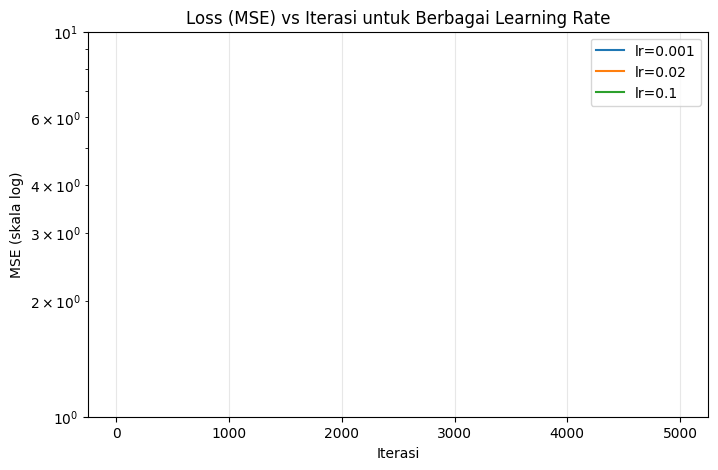

lr=0.001: loss akhir=20.236885721596426, koefisien finite=True
lr=0.02: loss akhir=18.213408164629325, koefisien finite=True
lr=0.1: loss akhir=nan, koefisien finite=False


In [ ]:
# Jawaban A5
learning_rates = [0.001, 0.02, 0.1]
gd_models = {}
gd_rows = []

for lr in learning_rates:
    model_gd = LinearRegressionGD(learning_rate=lr, n_iterations=5000).fit(X_train, y_train)
    gd_models[lr] = model_gd
    gd_rows.append({
        "Learning rate": lr,
        "Intercept": model_gd.intercept_,
        "Koefisien": model_gd.coef_[0],
        "MSE akhir": model_gd.loss_history_[-1]
    })

display(pd.DataFrame(gd_rows).round(5))
print(f"Normal Equation: intercept={b:.5f}, koefisien={m:.5f}")

plt.figure(figsize=(8, 5))
for lr, model_gd in gd_models.items():
    losses = model_gd.loss_history_
    # Plot nilai loss yang finite; nilai inf/nan menandakan divergensi.
    finite = np.isfinite(losses) & (losses > 0)
    if np.any(finite):
        plt.plot(np.where(finite)[0] + 1, losses[finite], label=f"lr={lr}")
plt.yscale("log")
plt.title("Loss (MSE) vs Iterasi untuk Berbagai Learning Rate")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

for lr, model_gd in gd_models.items():
    print(f"lr={lr}: loss akhir={model_gd.loss_history_[-1]}, "
          f"koefisien finite={np.all(np.isfinite(model_gd.coef_))}")


**Jawaban A5 (analisis):**

Learning rate `0.001` biasanya bergerak lebih lambat menuju nilai minimum, sehingga setelah 5.000 iterasi hasilnya dapat belum sepenuhnya sama dengan normal equation. Learning rate `0.02` pada eksperimen ini diharapkan lebih cepat mencapai nilai yang mendekati solusi normal equation. Learning rate `0.1` terlalu besar untuk skala fitur dan target yang digunakan, sehingga pembaruan parameter dapat melewati titik minimum berulang kali dan menyebabkan loss membesar atau menjadi `inf`/`NaN` (divergen). Jika muncul peringatan overflow, itu berarti nilai antara perhitungan menjadi terlalu besar untuk direpresentasikan secara numerik. Learning rate yang sesuai bergantung pada skala data; normalisasi fitur dapat membantu stabilitas.


### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

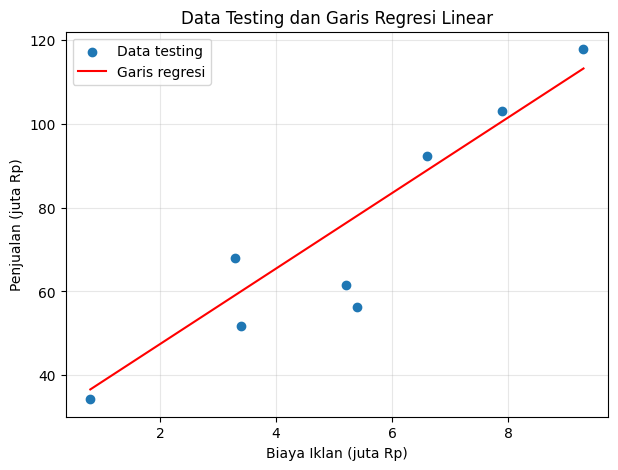

,BiayaIklan (juta Rp),Prediksi Penjualan (juta Rp)
0,4.5,69.968
1,7.0,92.488
2,12.0,137.529


In [ ]:
# Jawaban A6
plt.figure(figsize=(7, 5))
plt.scatter(X_test[:, 0], y_test, label="Data testing")
x_line = np.linspace(X_test.min(), X_test.max(), 100).reshape(-1, 1)
plt.plot(x_line[:, 0], linear_model.predict(x_line), color="red", label="Garis regresi")
plt.title("Data Testing dan Garis Regresi Linear")
plt.xlabel("Biaya Iklan (juta Rp)")
plt.ylabel("Penjualan (juta Rp)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

biaya_baru = np.array([[4.5], [7.0], [12.0]])
prediksi_penjualan = linear_model.predict(biaya_baru)
display(pd.DataFrame({
    "BiayaIklan (juta Rp)": biaya_baru[:, 0],
    "Prediksi Penjualan (juta Rp)": prediksi_penjualan
}).round(3))


**Jawaban A6 (analisis):**

Prediksi untuk biaya iklan 4,5 juta dan 7 juta lebih dapat dipercaya apabila nilainya masih berada di dalam rentang biaya iklan yang diamati dan hubungan linear cukup sesuai. Prediksi untuk 12 juta merupakan ekstrapolasi jika nilainya berada di luar rentang data. Hasil ekstrapolasi lebih tidak pasti karena pola hubungan pada data yang tersedia belum tentu berlanjut pada biaya iklan yang lebih tinggi. Karena itu, prediksi 12 juta sebaiknya diperlakukan sebagai perkiraan awal, bukan jaminan penjualan.


---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1



Jumlah setiap kelas:


,Jumlah
Spam,
Bukan Spam,35
Spam,25


Shape X: (60, 2) | Shape y: (60,)


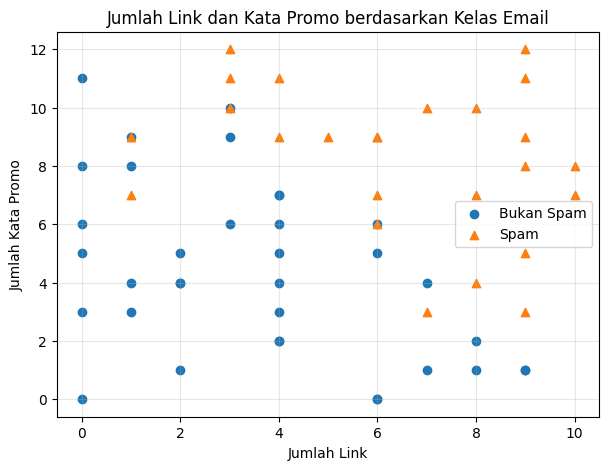

In [ ]:
# Jawaban B1
emails = pd.read_csv("Email_Data.csv")
display(emails.head())
print("\nJumlah setiap kelas:")
display(emails["Spam"].value_counts().rename(index={0: "Bukan Spam", 1: "Spam"}).to_frame("Jumlah"))

X_cls = emails[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
y_cls = emails["Spam"].to_numpy(dtype=int)
print("Shape X:", X_cls.shape, "| Shape y:", y_cls.shape)

plt.figure(figsize=(7, 5))
for label, name, marker in [(0, "Bukan Spam", "o"), (1, "Spam", "^")]:
    mask = y_cls == label
    plt.scatter(X_cls[mask, 0], X_cls[mask, 1], label=name, marker=marker)
plt.title("Jumlah Link dan Kata Promo berdasarkan Kelas Email")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

X_train: (45, 2) | X_test: (15, 2)
y_train: (45,) | y_test: (15,)


Intercept (b): -8.59181
Koefisien m1 (JumlahLink): 0.77071
Koefisien m2 (KataPromo): 0.73622
P(Spam) = sigmoid(-8.59181 + (0.77071 × JumlahLink) + (0.73622 × KataPromo))


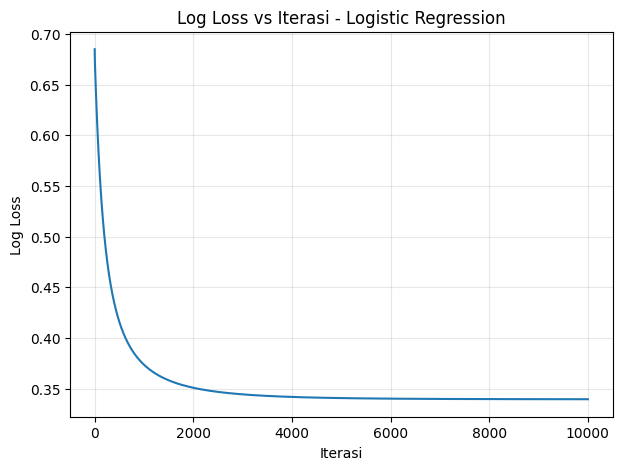

Log loss awal: 0.68482
Log loss akhir: 0.33964


In [ ]:
# Jawaban B2
X_train_cls, X_test_cls, y_train_cls, y_test_cls = train_test_split(
    X_cls, y_cls, test_size=0.25, random_state=RANDOM_STATE
)
print("X_train:", X_train_cls.shape, "| X_test:", X_test_cls.shape)
print("y_train:", y_train_cls.shape, "| y_test:", y_test_cls.shape)

log_model = LogisticRegression(learning_rate=0.1, n_iterations=10000)
log_model.fit(X_train_cls, y_train_cls)
b_log = log_model.intercept_
m1, m2 = log_model.coef_
print(f"Intercept (b): {b_log:.5f}")
print(f"Koefisien m1 (JumlahLink): {m1:.5f}")
print(f"Koefisien m2 (KataPromo): {m2:.5f}")
print(f"P(Spam) = sigmoid({b_log:.5f} + ({m1:.5f} × JumlahLink) + ({m2:.5f} × KataPromo))")

plt.figure(figsize=(7, 5))
plt.plot(np.arange(1, len(log_model.loss_history_) + 1), log_model.loss_history_)
plt.title("Log Loss vs Iterasi - Logistic Regression")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(alpha=0.3)
plt.show()
print(f"Log loss awal: {log_model.loss_history_[0]:.5f}")
print(f"Log loss akhir: {log_model.loss_history_[-1]:.5f}")


**Jawaban B2 (analisis):**

Model menghitung probabilitas email termasuk spam berdasarkan kombinasi jumlah link dan jumlah kata promosi. Fungsi sigmoid mengubah skor linear menjadi probabilitas antara 0 dan 1. Jika grafik log loss menurun lalu relatif stabil, berarti model belajar mengurangi kesalahan prediksi dan mulai konvergen. Koefisien positif berarti kenaikan fitur tersebut meningkatkan skor spam ketika fitur lain tetap, sedangkan koefisien negatif berarti menurunkannya.


### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [ ]:
# Jawaban B3
y_test_pred = log_model.predict(X_test_cls, threshold=0.5)
metrics = classification_metrics(y_test_cls, y_test_pred)
cm = confusion_matrix(y_test_cls, y_test_pred)
print("Confusion matrix [[TN, FP], [FN, TP]]:")
print(cm)
display(pd.DataFrame([metrics]).round(4))


Confusion matrix [[TN, FP], [FN, TP]]:
[[10  0]
 [ 0  5]]


,Accuracy,Precision,Recall,F1-score,TN,FP,FN,TP
0,1.0,1.0,1.0,1.0,10,0,0,5


**Jawaban B3 (analisis):**

FP (*false positive*) adalah email bukan spam yang salah ditandai sebagai spam. Akibatnya, pesan penting dapat masuk ke folder spam dan terlewat oleh pengguna. FN (*false negative*) adalah email spam yang salah diklasifikasikan sebagai bukan spam, sehingga pesan yang tidak diinginkan dapat masuk ke kotak masuk. Untuk filter email umum, FP sering dianggap sangat merugikan karena dapat menyembunyikan pesan penting, tetapi FN juga berisiko karena dapat membiarkan penipuan atau tautan berbahaya lolos. Pilihan prioritas bergantung pada tujuan dan kebutuhan pengguna.


### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

Decision boundary: KataPromo = -(-8.59181 + (0.77071 × JumlahLink)) / (0.73622)
Atau: KataPromo = 11.67016 + (-1.04684 × JumlahLink)


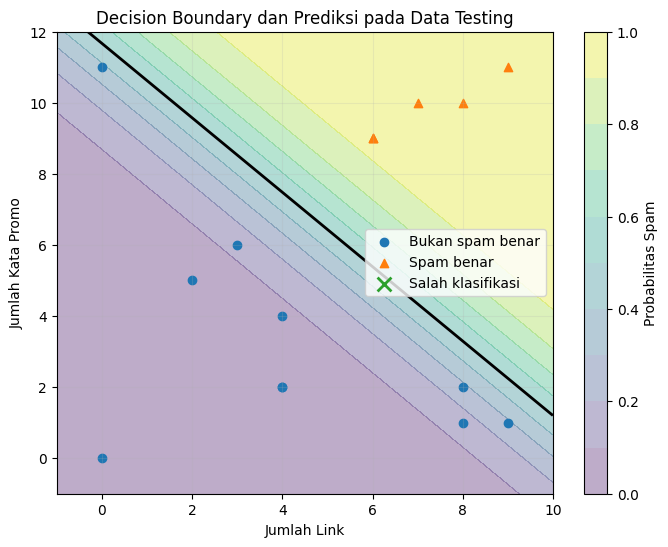

Data testing yang salah diklasifikasikan:


,JumlahLink,KataPromo,Spam aktual,Prediksi


In [ ]:
# Jawaban B4
if abs(m2) < 1e-12:
    print("Koefisien m2 mendekati nol; decision boundary tidak dapat ditulis sebagai x2 = -(b + m1*x1)/m2.")
else:
    print(f"Decision boundary: KataPromo = -({b_log:.5f} + ({m1:.5f} × JumlahLink)) / ({m2:.5f})")
    print(f"Atau: KataPromo = {(-b_log/m2):.5f} + ({(-m1/m2):.5f} × JumlahLink)")

x1_min, x1_max = X_test_cls[:, 0].min() - 1, X_test_cls[:, 0].max() + 1
x2_min, x2_max = X_test_cls[:, 1].min() - 1, X_test_cls[:, 1].max() + 1
xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 200),
                       np.linspace(x2_min, x2_max, 200))
grid = np.c_[xx1.ravel(), xx2.ravel()]
probs = log_model.predict_proba(grid).reshape(xx1.shape)

plt.figure(figsize=(8, 6))
plt.contourf(xx1, xx2, probs, levels=np.linspace(0, 1, 11), alpha=0.35)
plt.colorbar(label="Probabilitas Spam")
plt.contour(xx1, xx2, probs, levels=[0.5], colors="black", linewidths=2)
correct = y_test_pred == y_test_cls
plt.scatter(X_test_cls[correct & (y_test_cls == 0), 0], X_test_cls[correct & (y_test_cls == 0), 1],
            marker="o", label="Bukan spam benar")
plt.scatter(X_test_cls[correct & (y_test_cls == 1), 0], X_test_cls[correct & (y_test_cls == 1), 1],
            marker="^", label="Spam benar")
plt.scatter(X_test_cls[~correct, 0], X_test_cls[~correct, 1],
            marker="x", s=100, linewidths=2, label="Salah klasifikasi")
plt.title("Decision Boundary dan Prediksi pada Data Testing")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

print("Data testing yang salah diklasifikasikan:")
misclassified = pd.DataFrame(X_test_cls[~correct], columns=["JumlahLink", "KataPromo"])
misclassified["Spam aktual"] = y_test_cls[~correct]
misclassified["Prediksi"] = y_test_pred[~correct]
display(misclassified if len(misclassified) else pd.DataFrame(columns=["JumlahLink", "KataPromo", "Spam aktual", "Prediksi"]))


**Jawaban B4 (analisis):**

Garis decision boundary menunjukkan kombinasi jumlah link dan kata promosi saat probabilitas spam sama dengan 0,5. Titik di sisi dengan probabilitas lebih besar atau sama dengan 0,5 diklasifikasikan sebagai spam, sedangkan titik di sisi lainnya diklasifikasikan sebagai bukan spam. Titik bertanda silang pada grafik adalah data testing yang prediksinya tidak sama dengan label sebenarnya; tabel di bawah grafik menampilkan rincian kesalahan tersebut.


### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [ ]:
# Jawaban B5
prob_test = log_model.predict_proba(X_test_cls)
threshold_rows = []
threshold_predictions = {}
for threshold in [0.3, 0.5, 0.7]:
    pred = (prob_test >= threshold).astype(int)
    threshold_predictions[threshold] = pred
    met = classification_metrics(y_test_cls, pred)
    threshold_rows.append({
        "Threshold": threshold,
        "TN": met["TN"], "FP": met["FP"], "FN": met["FN"], "TP": met["TP"],
        "Precision": met["Precision"], "Recall": met["Recall"]
    })
threshold_table = pd.DataFrame(threshold_rows)
display(threshold_table.round(4))


,Threshold,TN,FP,FN,TP,Precision,Recall
0,0.3,9,1,0,5,0.8333,1.0
1,0.5,10,0,0,5,1.0000,1.0
2,0.7,10,0,0,5,1.0000,1.0


**Jawaban B5 (analisis):**

Menurunkan threshold menjadi 0,3 membuat model lebih mudah menandai email sebagai spam. Biasanya recall meningkat karena lebih banyak spam terdeteksi, tetapi FP dapat bertambah sehingga precision bisa turun. Menaikkan threshold menjadi 0,7 membuat model lebih ketat dalam memberi label spam; biasanya precision meningkat, tetapi sebagian spam dapat terlewat sehingga recall turun. Pilih threshold berdasarkan tabel hasil eksperimen. Untuk filter yang mengutamakan agar pesan penting tidak salah masuk folder spam, threshold 0,7 dapat dipertimbangkan; jika lebih mengutamakan deteksi spam, threshold 0,3 dapat dipertimbangkan.


### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [ ]:
# Jawaban B6
# Pilihan awal threshold = 0.7 untuk mengurangi risiko email bukan spam salah ditandai spam.
# Jika analisis B5 menunjukkan kebutuhan yang berbeda, ubah nilai THRESHOLD_PILIHAN.
THRESHOLD_PILIHAN = 0.7
email_baru = pd.DataFrame({
    "Email": ["E1", "E2", "E3", "E4"],
    "JumlahLink": [1, 5, 9, 2],
    "KataPromo": [2, 6, 10, 11]
})
X_baru = email_baru[["JumlahLink", "KataPromo"]].to_numpy(dtype=float)
email_baru["Probabilitas Spam"] = log_model.predict_proba(X_baru)
email_baru["Prediksi Angka"] = (email_baru["Probabilitas Spam"] >= THRESHOLD_PILIHAN).astype(int)
email_baru["Prediksi Kelas"] = email_baru["Prediksi Angka"].map({0: "Bukan Spam", 1: "Spam"})
email_baru["Threshold"] = THRESHOLD_PILIHAN
display(email_baru.round(4))


,Email,JumlahLink,KataPromo,Probabilitas Spam,Prediksi Angka,Prediksi Kelas,Threshold
0,E1,1,2,0.0017,0,Bukan Spam,0.7
1,E2,5,6,0.4204,0,Bukan Spam,0.7
2,E3,9,10,0.9967,1,Spam,0.7
3,E4,2,11,0.7404,1,Spam,0.7


**Jawaban C1:**

Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk memprediksi kelas, misalnya spam atau bukan spam, bukan nilai kontinu. Model menghitung kombinasi linear dari fitur, kemudian fungsi sigmoid mengubahnya menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas akhir. Nama “regression” merujuk pada cara model memperkirakan probabilitas melalui fungsi matematis.

**Jawaban C2:**

Normal equation menghitung parameter regresi secara langsung melalui operasi matriks tanpa proses iterasi. Gradient descent memperbarui parameter sedikit demi sedikit berdasarkan gradien loss, sehingga hasilnya dipengaruhi learning rate dan jumlah iterasi. Normal equation praktis untuk dataset kecil dengan jumlah fitur terbatas. Gradient descent lebih sesuai untuk dataset besar atau jumlah fitur yang banyak, terutama jika matriks perhitungan langsung mahal.

**Jawaban C3:**

Data training digunakan untuk mempelajari pola, sehingga evaluasi hanya pada data training dapat memberi gambaran yang terlalu optimistis. Data testing dipisahkan dan tidak digunakan saat pelatihan, sehingga lebih baik untuk memperkirakan kinerja model pada data baru. Overfitting terjadi ketika model terlalu menyesuaikan diri dengan data training, termasuk noise, sehingga kinerjanya menurun pada data yang belum pernah dilihat. Perbedaan kinerja training dan testing dapat menjadi tanda overfitting.

**Jawaban C4:**

Linear Regression memprediksi nilai kontinu, sehingga MSE menghitung rata-rata kuadrat selisih antara nilai aktual dan prediksi. Pengkuadratan memberi penalti lebih besar pada kesalahan yang besar dan menghasilkan fungsi loss yang mudah dioptimalkan. Logistic Regression menghasilkan probabilitas kelas, sehingga log loss mengukur kualitas probabilitas yang diberikan untuk label sebenarnya. Log loss memberi penalti besar ketika model sangat yakin pada prediksi yang salah.

**Jawaban C5:**

Hasil dapat berbeda karena pembagian data training dan testing dipengaruhi `random_state`. Pembagian yang berbeda mengubah data yang dipakai untuk melatih model sehingga koefisien dan metrik evaluasi juga dapat berubah. Hasil juga dapat dipengaruhi inisialisasi parameter, learning rate, jumlah iterasi, urutan pembaruan, dan detail implementasi. Karena itu, perbandingan yang adil memerlukan pembagian data dan pengaturan eksperimen yang sama.


**Jawaban C1:**

**Jawaban C2:**

**Jawaban C3:**

**Jawaban C4:**

**Jawaban C5:**

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [ ]:
# Jawaban Bonus
try:
    from sklearn.linear_model import LinearRegression as SklearnLinearRegression
    from sklearn.linear_model import LogisticRegression as SklearnLogisticRegression
    from sklearn.metrics import accuracy_score as sk_accuracy_score, mean_squared_error, r2_score

    sk_linear = SklearnLinearRegression().fit(X_train, y_train)
    sk_train_pred = sk_linear.predict(X_train)
    sk_test_pred = sk_linear.predict(X_test)
    print("=== Linear Regression: implementasi sendiri vs scikit-learn ===")
    print(f"Implementasi sendiri: intercept={linear_model.intercept_:.5f}, koefisien={linear_model.coef_[0]:.5f}")
    print(f"scikit-learn       : intercept={sk_linear.intercept_:.5f}, koefisien={sk_linear.coef_[0]:.5f}")
    print(f"R2 testing sendiri={regression_metrics(y_test, linear_model.predict(X_test))['R2']:.5f}; "
          f"scikit-learn={r2_score(y_test, sk_test_pred):.5f}")

    # penalty=None agar perbandingan mendekati logistic regression tanpa regularisasi.
    try:
        sk_log = SklearnLogisticRegression(penalty=None, max_iter=10000, tol=1e-10)
        sk_log.fit(X_train_cls, y_train_cls)
    except (TypeError, ValueError):
        # Kompatibilitas dengan versi scikit-learn yang masih memakai penalty='none'.
        sk_log = SklearnLogisticRegression(penalty="none", max_iter=10000, tol=1e-10)
        sk_log.fit(X_train_cls, y_train_cls)

    sk_log_pred = sk_log.predict(X_test_cls)
    print("\n=== Logistic Regression: implementasi sendiri vs scikit-learn ===")
    print(f"Implementasi sendiri: intercept={log_model.intercept_:.5f}, koefisien={log_model.coef_}")
    print(f"scikit-learn       : intercept={sk_log.intercept_[0]:.5f}, koefisien={sk_log.coef_[0]}")
    print(f"Accuracy testing sendiri={accuracy_score(y_test_cls, y_test_pred):.5f}; "
          f"scikit-learn={sk_accuracy_score(y_test_cls, sk_log_pred):.5f}")
except ImportError:
    print("scikit-learn belum tersedia. Instal library ini hanya untuk menjalankan bagian bonus.")


=== Linear Regression: implementasi sendiri vs scikit-learn ===
Implementasi sendiri: intercept=29.43107, koefisien=9.00815
scikit-learn       : intercept=29.43107, koefisien=9.00815
R2 testing sendiri=0.84458; scikit-learn=0.84458

=== Logistic Regression: implementasi sendiri vs scikit-learn ===
Implementasi sendiri: intercept=-8.59181, koefisien=[0.7707 0.7362]
scikit-learn       : intercept=-8.78570, koefisien=[0.7879 0.7522]
Accuracy testing sendiri=1.00000; scikit-learn=1.00000


/opt/pyvenv/lib/python3.13/site-packages/sklearn/linear_model/_logistic.py:1135: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', and C=np.inf instead of penalty=None.
  warnings.warn(


**Jawaban Bonus (analisis):**

Pada Linear Regression, hasil normal equation sendiri seharusnya sangat dekat dengan `scikit-learn` karena keduanya meminimalkan jumlah kuadrat kesalahan dengan regresi linear. Hasil Logistic Regression dapat berbeda jika pengaturan optimasi tidak sama. Secara default, `scikit-learn` menggunakan regularisasi pada Logistic Regression; regularisasi dapat mengubah koefisien dan probabilitas. Pada kode bonus digunakan `penalty=None` jika didukung agar perbandingan lebih dekat dengan model tanpa regularisasi. Perbedaan kecil masih dapat muncul karena toleransi konvergensi dan algoritma optimasi yang digunakan.
